# 02 - Verification loop: checando o relatório antes de entregar

No notebook anterior, o agente respondeu e o loop terminou. Ninguém conferiu se a resposta estava certa.

O **verification loop** acrescenta um passo de verificação. Um verificador independente confere o relatório com critérios próprios. Se reprovar, o analista recebe os problemas e refaz o relatório. O ciclo para quando o relatório é aprovado ou quando o número máximo de tentativas acaba.

Fluxo:

```
START → analista → verificador → aprovado? → sim → END
                                 → não, ainda há tentativas → analista (com os problemas)
                                 → não, sem tentativas → END (entregue com ressalvas)
```

O verificador tem duas etapas:

1. **Regras determinísticas**, sem LLM: o relatório tem as seções obrigatórias e todo valor em R$ aparece nos dados das ferramentas.
2. **Juiz com LLM**, que confere se cada afirmação tem apoio nos dados e se a recomendação é justificada. Só roda se as regras passarem.

Os dados continuam simulados, como no notebook 01, e o tema é o mesmo: preço do milho.

## 1. Configuração

A chave e o modelo vêm do `.env` na raiz do projeto, como nos outros notebooks.

O rastreamento usa o MLflow com um banco SQLite, `mlflow.db`, criado na pasta deste notebook. Cada execução do grafo vira um trace, com as tentativas do analista e as decisões do verificador.

In [1]:
import json
import os
import re
import unicodedata
from typing import TypedDict

from dotenv import find_dotenv, load_dotenv
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

from IPython.display import Markdown, display
from IPython.display import Image

import mlflow

from deepagents import create_deep_agent

load_dotenv(find_dotenv())

mlflow.set_tracking_uri("sqlite:///mlflow.db")
EXPERIMENTO = "verification-loop-milho"
experimento = mlflow.set_experiment(EXPERIMENTO)
mlflow.langchain.autolog()

llm = ChatOpenAI(
    model=os.getenv("OPENAI_MODEL", "gpt-5-mini"),
    api_key=os.getenv("OPENAI_API_KEY"),
)

2026/11/17 19:29:00 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at /home/leonardo/Documentos/github/loop_engineering_study/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/mlflow-trace-instrumentation/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## 2. Dados simulados e ferramentas

Os dados são fictícios e ficam em dicionários, como no notebook 01. As ferramentas são as mesmas: preço, clima e estoques.

In [2]:
PRECOS_SACA = {
    "paranagua": {"praca": "Paranaguá (PR)", "preco_rs_saca": 118.50, "variacao_7_dias_pct": 1.8},
    "cascavel": {"praca": "Cascavel (PR)", "preco_rs_saca": 112.30, "variacao_7_dias_pct": 2.4},
    "rio verde": {"praca": "Rio Verde (GO)", "preco_rs_saca": 108.90, "variacao_7_dias_pct": 0.6},
    "campinas": {"praca": "Campinas (SP)", "preco_rs_saca": 120.10, "variacao_7_dias_pct": -0.9},
}

CLIMA = {
    "parana": {"regiao": "Oeste do Paraná", "chuva_ultimos_7_dias_mm": 12, "chuva_prevista_15_dias_mm": 18,
               "risco": "baixo", "observacao": "Chuva irregular no fim do mês, sem sinal de seca forte."},
    "mato grosso": {"regiao": "Mato Grosso", "chuva_ultimos_7_dias_mm": 4, "chuva_prevista_15_dias_mm": 6,
                    "risco": "alto", "observacao": "Veranico prolongado, risco de perda na segunda safra."},
    "goias": {"regiao": "Goiás", "chuva_ultimos_7_dias_mm": 7, "chuva_prevista_15_dias_mm": 10,
              "risco": "médio", "observacao": "Chuva abaixo da média para a época."},
}

ESTOQUES = {
    "safra_estimada_mil_t": 128_000,
    "consumo_estimado_mil_t": 79_000,
    "estoque_inicial_mil_t": 21_000,
    "exportacao_estimada_mil_t": 42_000,
    "estoque_final_estimado_mil_t": 28_000,
    "relacao_estoque_consumo_pct": 35.4,
    "leitura": "Estoque final abaixo da média dos últimos 5 anos.",
}


@tool
def consultar_preco_milho(praca: str) -> str:
    """Consulta o preço spot do milho em uma praça. Praças válidas: paranagua, cascavel, rio verde, campinas."""
    chave = praca.lower().strip()
    if chave not in PRECOS_SACA:
        return json.dumps({"erro": f"Praça '{praca}' não encontrada.", "pracas_validas": list(PRECOS_SACA)}, ensure_ascii=False)
    return json.dumps(PRECOS_SACA[chave], ensure_ascii=False)


@tool
def consultar_clima(regiao: str) -> str:
    """Consulta a chuva recente, a previsão e o risco climático de uma região produtora. Regiões válidas: parana, mato grosso, goias."""
    chave = regiao.lower().strip()
    if chave not in CLIMA:
        return json.dumps({"erro": f"Região '{regiao}' não encontrada.", "regioes_validas": list(CLIMA)}, ensure_ascii=False)
    return json.dumps(CLIMA[chave], ensure_ascii=False)


@tool
def consultar_estoques() -> str:
    """Consulta o balanço de oferta e demanda do milho no Brasil: safra, consumo, exportação e estoque final."""
    return json.dumps(ESTOQUES, ensure_ascii=False)


FERRAMENTAS = [consultar_preco_milho, consultar_clima, consultar_estoques]

## 3. Analista

O analista é o deep agent do notebook 01, com as mesmas ferramentas. Ele é um nó do grafo. Cada vez que o nó roda, o agente recebe a pergunta e, nas tentativas seguintes, também os problemas apontados pelo verificador e o relatório anterior.

O nó guarda no estado só o relatório e as **evidências**: o conteúdo devolvido pelas ferramentas. As evidências são o que o verificador usa para conferir o relatório.

Para o loop ser visível, a primeira tentativa sai com um erro introduzido de propósito: um preço em R$ é trocado por um valor 10% maior. O erro é aplicado depois que o agente responde, e não pelo prompt, porque um modelo pode não errar quando pedido. Assim o verificador tem o que corrigir na primeira volta. Para desligar a demonstração, troque `ERRO_INTENCIONAL` para `False`.

In [3]:
agente = create_deep_agent(
    model=llm,
    tools=FERRAMENTAS,
    system_prompt=(
        "Você é um analista do mercado de milho. "
        "Antes de concluir, use as ferramentas para reunir os dados: preços em pelo menos duas praças, "
        "o clima de pelo menos uma região produtora e o balanço de estoques. "
        "Quando tiver os dados, escreva em português um relatório curto com as seções: "
        "situação dos preços, risco climático, leitura dos estoques e recomendação (vender, comprar ou aguardar), "
        "com a justificativa. Use somente valores que vieram das ferramentas. Lembre que os dados são simulados."
    ),
)

PERGUNTA = "Como está o mercado de milho agora e qual deve ser a recomendação para um produtor do Paraná?"
MAX_TENTATIVAS = 3

# Demonstração: na primeira tentativa, o analista erra de propósito um preço.
# Sem esse erro, o modelo costuma acertar de primeira e o verificador não tem o que corrigir.
ERRO_INTENCIONAL = True


def introduzir_erro(relatorio: str) -> str:
    # troca o primeiro valor em R$ por um 10% maior
    def trocar(m):
        valor = converter_valor(m.group(1)) * 1.1
        return f"R$ {valor:.2f}".replace(".", ",")

    return re.sub(r"R\$\s?(\d+(?:[.,]\d+)*)", trocar, relatorio, count=1)


class Estado(TypedDict):
    relatorio: str
    evidencias: list[str]
    tentativas: int
    feedback: str
    verificacao: dict


def analista(estado: Estado) -> dict:
    pergunta = PERGUNTA
    if estado.get("feedback"):
        pergunta += (
            "\n\nA verificação do relatório anterior reprovou. Este era o relatório anterior:\n"
            f"{estado['relatorio']}\n\n"
            f"Corrija os problemas abaixo e refaça o relatório, usando somente dados das ferramentas:\n"
            f"{estado['feedback']}"
        )

    resultado = agente.invoke({"messages": [HumanMessage(content=pergunta)]})
    mensagens = resultado["messages"]
    relatorio = mensagens[-1].content
    if ERRO_INTENCIONAL and estado.get("tentativas", 0) == 0:
        relatorio = introduzir_erro(relatorio)
        print("[demonstração] o analista errou de propósito na primeira tentativa")
    return {
        "relatorio": relatorio,
        "evidencias": [m.content for m in mensagens if isinstance(m, ToolMessage)],
        "tentativas": estado.get("tentativas", 0) + 1,
    }

## 4. Verificador

### 4.1. Regras determinísticas

Estas regras são exatas e baratas. Elas não dependem do modelo:

- **Seções obrigatórias**: o relatório precisa falar de preço, clima, estoques e recomendação. Os termos são comparados sem acento e sem maiúsculas.
- **Valores em R$**: cada valor escrito como `R$ 118,50` precisa existir nas evidências. Os números dos dados vêm em formato `118.5`, então a comparação é feita com float e com duas casas decimais.

A função devolve a lista de problemas. Lista vazia significa que as regras passaram.

In [4]:
SECOES_OBRIGATORIAS = {
    "preços": ["preco", "precos"],
    "clima": ["clima", "climatic", "chuva"],
    "estoques": ["estoque"],
    "recomendação": ["recomend"],
}


def sem_acento(texto: str) -> str:
    texto = unicodedata.normalize("NFKD", texto)
    return "".join(c for c in texto if not unicodedata.combining(c)).lower()


def converter_valor(texto: str) -> float:
    # aceita o formato brasileiro (1.250,40) e o formato com ponto decimal (118.5)
    if "," in texto:
        return float(texto.replace(".", "").replace(",", "."))
    return float(texto)


def regras_deterministicas(relatorio: str, evidencias: list[str]) -> list[str]:
    problemas = []
    texto = sem_acento(relatorio)

    for secao, termos in SECOES_OBRIGATORIAS.items():
        if not any(termo in texto for termo in termos):
            problemas.append(f"Falta a seção sobre {secao}.")

    dados = " ".join(evidencias)
    numeros_dados = {round(float(n), 2) for n in re.findall(r"\d+\.\d+", dados)}
    for valor_texto in re.findall(r"R\$\s?(\d+(?:[.,]\d+)*)", relatorio):
        valor = round(converter_valor(valor_texto), 2)
        if valor not in numeros_dados:
            problemas.append(f"O valor R$ {valor_texto} não aparece nos dados das ferramentas.")

    return problemas

### 4.2. Juiz com LLM

Quando as regras passam, um segundo passo confere o conteúdo. O juiz usa saída estruturada com Pydantic, então a resposta sempre vem como `aprovado` (sim ou não) e uma lista de problemas.

O juiz não gera relatório. Ele só lê as evidências e o relatório, e aponta o que não tem apoio nos dados.

In [5]:
class Avaliacao(BaseModel):
    aprovado: bool = Field(description="True se todas as afirmações têm apoio nas evidências e a recomendação é justificada.")
    problemas: list[str] = Field(description="Problemas concretos encontrados. Lista vazia se aprovado.")


juiz = llm.with_structured_output(Avaliacao)


def verificador(estado: Estado) -> dict:
    problemas = regras_deterministicas(estado["relatorio"], estado["evidencias"])

    if not problemas:
        evidencias = "\n".join(estado["evidencias"])
        avaliacao = juiz.invoke([
            SystemMessage(content=(
                "Você revisa relatórios de mercado. Aprove somente se cada afirmação tiver apoio nas evidências, "
                "se nenhum dado foi inventado e se a recomendação for justificada pelos dados. "
                "Se reprovar, liste problemas concretos e curtos."
            )),
            HumanMessage(content=f"Evidências das ferramentas:\n{evidencias}\n\nRelatório:\n{estado['relatorio']}"),
        ])
        problemas = [] if avaliacao.aprovado else (avaliacao.problemas or ["Juiz reprovou sem apontar motivo."])

    return {
        "verificacao": {"aprovado": not problemas, "problemas": problemas},
        "feedback": "\n".join(f"- {p}" for p in problemas),
    }

## 5. Montando o grafo

A aresta condicional decide o próximo passo:

- aprovado → `END`;
- reprovado e ainda há tentativas → volta ao `analista`;
- reprovado e sem tentativas → `END`, com o relatório marcado como entregue com ressalvas.

In [6]:
def decidir(estado: Estado) -> str:
    if estado["verificacao"]["aprovado"]:
        return END
    if estado["tentativas"] >= MAX_TENTATIVAS:
        return END
    return "analista"


grafo = StateGraph(Estado)
grafo.add_node("analista", analista)
grafo.add_node("verificador", verificador)
grafo.add_edge(START, "analista")
grafo.add_edge("analista", "verificador")
grafo.add_conditional_edges("verificador", decidir, {"analista": "analista", END: END})
app = grafo.compile()

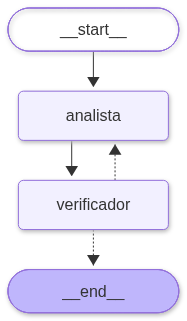

In [7]:
display(Image(app.get_graph().draw_mermaid_png()))

## 6. Executando o loop

O `stream` com `stream_mode="updates"` mostra cada nó assim que ele termina. A função `executar` acumula o estado final, que é usado no fim para mostrar o status.

In [8]:
@mlflow.trace(name="executar_loop")
def executar(pergunta: str = PERGUNTA) -> dict:
    global PERGUNTA
    PERGUNTA = pergunta
    estado = {"tentativas": 0, "feedback": "", "relatorio": "", "evidencias": []}

    for evento in app.stream({"tentativas": 0, "feedback": ""}, config={"recursion_limit": 30}, stream_mode="updates"):
        for no, atualizacao in evento.items():
            estado.update(atualizacao)
            if no == "analista":
                print(f"[tentativa {estado['tentativas']}] analista gerou um relatório de {len(estado['relatorio'])} caracteres")
            elif no == "verificador":
                verificacao = estado["verificacao"]
                if verificacao["aprovado"]:
                    print("    verificador: aprovado")
                else:
                    print("    verificador: reprovado")
                    for problema in verificacao["problemas"]:
                        print(f"      - {problema}")

    status = "aprovado" if estado["verificacao"]["aprovado"] else "entregue com ressalvas"
    print(f"\nStatus final: {status} após {estado['tentativas']} tentativa(s)")
    estado["trace_id"] = mlflow.get_active_trace_id()
    return estado


estado_final = executar()
print("\n--- Relatório final ---")
print(estado_final["relatorio"])

[demonstração] o analista errou de propósito na primeira tentativa
[tentativa 1] analista gerou um relatório de 1557 caracteres
    verificador: reprovado
      - O valor R$ 130,35 não aparece nos dados das ferramentas.


[tentativa 2] analista gerou um relatório de 1813 caracteres


    verificador: aprovado

Status final: aprovado após 2 tentativa(s)

--- Relatório final ---
Relatório rápido — produtor do Paraná
Dados simulados (valores das consultas)

1) Situação dos preços
- Paranaguá: R$ 118,5/saca (variação 7 dias: +1,8%).
- Cascavel: R$ 112,3/saca (variação 7 dias: +2,4%).
- (Referência adicional) Rio Verde: R$ 108,9/saca (variação 7 dias: +0,6%).
Interpretação: praças do Sul/Centro-Oeste apresentam preços firmes e ligeira alta nas últimas semanas.

2) Risco climático
- Região: Oeste do Paraná.
- Chuva últimos 7 dias: 12 mm.
- Chuva prevista (15 dias): 18 mm.
- Risco: baixo.
- Observação: "Chuva irregular no fim do mês, sem sinal de seca forte."

3) Leitura dos estoques (valores em mil t)
- Safra estimada: 128000 mil t.
- Consumo estimado: 79000 mil t.
- Estoque inicial: 21000 mil t.
- Exportação estimada: 42000 mil t.
- Estoque final estimado: 28000 mil t.
- Relação estoque/consumo: 35,4%.
- Leitura: "Estoque final abaixo da média dos últimos 5 anos."
Inter

## 7. Testando o verificador com um relatório errado

Para ver a verificação agindo, este teste passa um relatório com erros conhecidos direto para as regras, sem passar pelo agente:

- o preço de Paranaguá aparece como `R$ 125,00`, mas o dado é `R$ 118,50`;
- a seção de clima não existe.

As evidências vêm das próprias ferramentas, como no loop real.

In [9]:
evidencias_teste = [
    consultar_preco_milho.invoke({"praca": "paranagua"}),
    consultar_estoques.invoke({}),
]

relatorio_errado = (
    "Situação dos preços: Paranaguá (PR) está em R$ 125,00 por saca.\n"
    "Leitura dos estoques: estoque final de 28000 mil t, abaixo da média.\n"
    "Recomendação: vender parte da produção."
)

for problema in regras_deterministicas(relatorio_errado, evidencias_teste):
    print("-", problema)

- Falta a seção sobre clima.
- O valor R$ 125,00 não aparece nos dados das ferramentas.


## 8. Acompanhando o loop no MLflow

Cada execução do grafo virou um trace no experimento `verification-loop-milho`. Na árvore, cada tentativa aparece como uma passagem pelo `analista` e pelo `verificador`.

Para abrir a interface:

1. Abra um terminal na pasta `notebooks/05-LoopEngineering`.
2. Rode:

```bash
uv run --project ../.. mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

3. Abra `http://127.0.0.1:5000`, escolha o experimento `verification-loop-milho` e abra a aba **Traces**.
4. Pressione `Ctrl+C` para parar a interface.

A célula seguinte lê os traces pelo notebook.

In [10]:
mlflow.flush_trace_async_logging()  # garante que os traces já foram gravados

traces = mlflow.search_traces(experiment_ids=[experimento.experiment_id], max_results=10)
print(f"Traces registrados no experimento: {len(traces)}")

trace = mlflow.get_trace(estado_final["trace_id"])
nomes_nos = [s.name for s in trace.data.spans if s.name in ("analista", "verificador")]
print(f"Passagens pelos nós na última execução ({trace.info.trace_id}):")
print(" → ".join(nomes_nos))

Traces registrados no experimento: 10
Passagens pelos nós na última execução (tr-5f4112bb23bbc1be992cace9ba894cc2):
analista → verificador → analista → verificador


/tmp/ipykernel_55271/2001990799.py:3: FutureWarning: Parameter 'experiment_ids' is deprecated. Please use 'locations' instead.
  traces = mlflow.search_traces(experiment_ids=[experimento.experiment_id], max_results=10)


## Observações

- O verificador é independente do analista. Ele confere o resultado com regras e com um juiz separado, não confia no próprio texto do relatório.
- Regras determinísticas pegam erros exatos (valor errado, seção faltando) de graça. O juiz com LLM pega o que regra não cobre, como uma recomendação sem justificativa.
- O loop precisa de limite. `MAX_TENTATIVAS` limita as correções, e `recursion_limit` limita os passos do grafo. Sem limite, um verificador exigente demais poderia rodar para sempre.
- Quando o limite acaba sem aprovação, o sistema entrega com ressalvas em vez de travar. Em produção, essa saída pode ir para revisão humana.